# 03 — Embeddings

## Terms & Definitions
- **Embedding**: a learned mapping from a discrete token ID to a dense vector of real numbers — the model's internal representation of "what that token means."
- **Embedding table**: a big matrix of shape `(vocab_size, embedding_dim)` — one row per token in the vocabulary.
- **Positional embedding**: a vector added to each token's embedding that encodes *where* in the sequence that token sits (since attention itself, notebook 05, has no inherent notion of order).
- **Embedding dimension (`n_embd`)**: how many numbers represent each token — a key size/capacity knob of the whole model.

## Why Not Just Use Token IDs Directly?
Token IDs from notebook 02 are arbitrary integers — token 47 isn't "more" or "related to" token 48 in any meaningful way; they're just index labels. If we fed raw IDs into a neural network, the network would have no way to learn that, say, "battery" and "electricity" are related concepts, because their IDs are just unordered labels.

**Embeddings fix this** by giving every token ID its own learnable vector. During training, tokens that behave similarly in context end up with similar vectors — the network discovers relationships in this vector space entirely from data, with no one telling it "battery" and "electricity" are related.

## History
Word embeddings predate Transformers: **word2vec** (Mikolov et al., 2013) and **GloVe** (2014) showed that training a shallow model to predict neighboring words produces embeddings with striking geometric structure — the famous `king - man + woman ≈ queen` example. Transformers absorbed this idea directly: the very first layer of every LLM is an embedding table, now trained end-to-end as part of the whole network rather than as a separate pretraining step.

## The Math (light)
Looking up an embedding is just indexing into a matrix:

$$e_i = E[i]$$

where $E \in \mathbb{R}^{V \times d}$ is the embedding table ($V$ = vocab size, $d$ = embedding dimension) and $i$ is a token ID. In PyTorch this whole operation is `nn.Embedding`.


In [1]:
import sys
sys.path.insert(0, "..")

import torch
import torch.nn as nn

torch.manual_seed(0)

vocab_size = 10
embedding_dim = 4
embedding = nn.Embedding(vocab_size, embedding_dim)

print("embedding table shape:", embedding.weight.shape)
print(embedding.weight)


embedding table shape: torch.Size([10, 4])
Parameter containing:
tensor([[-1.1258, -1.1524, -0.2506, -0.4339],
        [ 0.8487,  0.6920, -0.3160, -2.1152],
        [ 0.3223, -1.2633,  0.3500,  0.3081],
        [ 0.1198,  1.2377,  1.1168, -0.2473],
        [-1.3527, -1.6959,  0.5667,  0.7935],
        [ 0.5988, -1.5551, -0.3414,  1.8530],
        [-0.2159, -0.7425,  0.5627,  0.2596],
        [-0.1740, -0.6787,  0.9383,  0.4889],
        [ 1.2032,  0.0845, -1.2001, -0.0048],
        [-0.5181, -0.3067, -1.5810,  1.7066]], requires_grad=True)


In [2]:
token_ids = torch.tensor([3, 7, 3])  # note: token 3 appears twice
vectors = embedding(token_ids)
print("looked-up vectors:\n", vectors)
print()
print("token 3 appears twice -- same vector both times:", torch.equal(vectors[0], vectors[2]))


looked-up vectors:
 tensor([[ 0.1198,  1.2377,  1.1168, -0.2473],
        [-0.1740, -0.6787,  0.9383,  0.4889],
        [ 0.1198,  1.2377,  1.1168, -0.2473]], grad_fn=<EmbeddingBackward0>)

token 3 appears twice -- same vector both times: True


This is the key point: an embedding table is just a lookup — but because it's made of learnable parameters, gradient descent (notebook 00) can adjust those vectors so that tokens which behave similarly in the training data end up nearby in vector space.

## Positional Embeddings

Attention (notebook 05) looks at *all* tokens in a sequence simultaneously with no built-in sense of order — "the cat sat" and "sat cat the" would look identical to raw attention. We fix this by adding a **positional embedding** — a vector representing "this is position 0 / 1 / 2 / ..." — on top of the token embedding.

Two common approaches:
- **Learned positional embeddings** (what GPT-2 and our `GPTMicro` use): just another embedding table, indexed by position 0, 1, 2, ..., trained like any other parameter.
- **Sinusoidal positional embeddings** (the original "Attention Is All You Need" paper): fixed (not learned) vectors built from sine/cosine waves of different frequencies, chosen so the model can mathematically deduce relative positions. Not learned, but requires no extra parameters and can in principle generalize to sequence lengths never seen during training.

We use learned positional embeddings for simplicity — see `src/model.py: GPTMicro.pos_emb`.


In [3]:
block_size = 8
pos_embedding = nn.Embedding(block_size, embedding_dim)

positions = torch.arange(block_size)
pos_vectors = pos_embedding(positions)
print("positional embedding table shape:", pos_vectors.shape)


positional embedding table shape: torch.Size([8, 4])


In [4]:
# The actual input to a transformer block: token embedding + positional embedding, added elementwise.
token_ids = torch.tensor([3, 7, 1, 9, 3, 0, 2, 5])  # a toy "sequence" of length block_size
tok_vectors = embedding(token_ids)

combined = tok_vectors + pos_vectors
print("token embeddings shape:     ", tok_vectors.shape)
print("positional embeddings shape:", pos_vectors.shape)
print("combined shape:             ", combined.shape)


token embeddings shape:      torch.Size([8, 4])
positional embeddings shape: torch.Size([8, 4])
combined shape:              torch.Size([8, 4])


## Visualizing an Embedding Space

Let's train a tiny embedding table (via a bigram-style prediction task, cf. notebook 01) and visualize it in 2D with PCA, to build intuition for "nearby vectors = related tokens."


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from src.data import load_electricity_for_boys, train_bpe_tokenizer

text = load_electricity_for_boys()
tokenizer = train_bpe_tokenizer(text, vocab_size=8000)

# A handful of words we expect to cluster meaningfully once trained.
words_of_interest = ["battery", "circuit", "wire", "current", "magnet", "coil",
                       "boy", "school", "book", "chapter", "wood", "iron"]

ids = []
labels = []
for w in words_of_interest:
    enc = tokenizer.encode(w).ids
    if len(enc) == 1:  # only keep words that are a single BPE token, for a clean plot
        ids.append(enc[0])
        labels.append(w)

print(f"kept {len(labels)}/{len(words_of_interest)} words that map to a single token:", labels)





kept 8/12 words that map to a single token: ['battery', 'circuit', 'wire', 'current', 'magnet', 'coil', 'wood', 'iron']


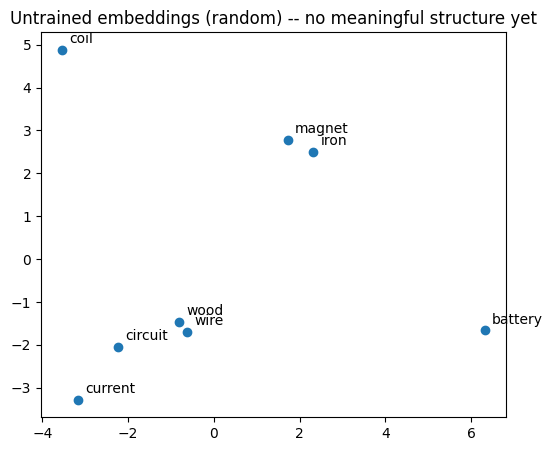

In [6]:
# NOTE: this embedding table is untrained (randomly initialized), so this plot
# shows *no* meaningful structure yet -- it's here to show what "before training"
# looks like. After pretraining (notebook 08), you could re-run this same PCA
# visualization on the trained model's `token_emb.weight` and compare.
untrained_embedding = nn.Embedding(tokenizer.get_vocab_size(), 32)
vectors = untrained_embedding(torch.tensor(ids)).detach().numpy()

coords = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(6, 5))
plt.scatter(coords[:, 0], coords[:, 1])
for (x, y), label in zip(coords, labels):
    plt.annotate(label, (x, y), textcoords="offset points", xytext=(5, 5))
plt.title("Untrained embeddings (random) -- no meaningful structure yet")
plt.show()


## Exercise
After you run notebook 08 (pretraining) and have a trained checkpoint, come back to this notebook, load the trained model, pull out `model.token_emb.weight`, and re-run the PCA plot above on the *trained* vectors instead of `untrained_embedding`. See if related words (like "battery"/"current"/"circuit") end up closer together than unrelated ones.

## Summary
- Token IDs are meaningless labels; embeddings turn them into vectors the network can reason over.
- Embedding tables are learned parameters — just a big matrix, indexed by token ID.
- Positional embeddings inject sequence order, since attention alone has none.
- `GPTMicro`'s input to its first Transformer block is `token_emb(x) + pos_emb(positions)` — see `src/model.py`.

Next: **04 — Neural Network Foundations** (the building blocks — linear layers, activations, normalization — that get assembled into a Transformer block).
